# 1.关于模型调用的invoke的使用


## 1.invoke的传参

In [1]:
import os

from dotenv import load_dotenv
from langchain.chat_models import init_chat_model
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage
from openai import base_url
from pyexpat.errors import messages

load_dotenv(override=True)
DEEPSEEK_API_KEY = os.getenv("DEEPSEEK_API_KEY")
DEEPSEEK_API_BASE = os.getenv("DEEPSEEK_API_BASE")
model = init_chat_model(
    model="deepseek:deepseek-flash",
    api_key=DEEPSEEK_API_KEY,
    base_url=DEEPSEEK_API_BASE
)
# 向模型发送单条数据
prompt = "翻译成英文：你好世界"
response = model.invoke(prompt)
print(response)

content='Hello, world.' additional_kwargs={'refusal': None, 'reasoning_content': 'The user wants me to translate "你好世界" from Chinese into English. This is a simple, well-known phrase that\'s commonly used as a greeting or as a first program output in programming.\n\nLooking at the Chinese text "你好世界", it\'s a direct combination of the greeting "你好" (hello) and "世界" (world). The natural English equivalent is "Hello, world" or "Hello World". This is such a standard phrase that it\'s almost a direct word-for-word correspondence.\n\nSince the text is very short and the meaning is clear, I just need to provide the English translation.'} response_metadata={'token_usage': {'completion_tokens': 127, 'prompt_tokens': 36, 'total_tokens': 163, 'completion_tokens_details': {'accepted_prediction_tokens': None, 'audio_tokens': None, 'reasoning_tokens': 122, 'rejected_prediction_tokens': None}, 'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 0}, 'prompt_cache_hit_tokens': 0, 'prompt_

## 2.字典列表【最灵活】
创建字典列表组成消息，一条消息通常包含role(角色)、content(内容)等信息
使用场景：可以设置系统提示，表达多轮对话历史，JSON兼容，易于序列化和网络传输，生产环境推荐
缺点：代码稍微多一点但更清晰

messages = [
    {"role":"system","content":"系统提示"},
    {"role":"user","content":"用户消息"},
    {"role":"assistant","content":"AI回复"},
    {"role":"user","content":"继续提问"},
]
### system的作用是设定ai的行为、角色、规则，示例：你是一个专业的python导师
### user的作用的是用户的输入/问题
### assistant的作用的是ai的历史回复，用于对话上下文

In [5]:
messages = [
    {"role":"system","content":"你是一个专业的物理老师"},
    {"role":"user","content":"请你解释一下1kg铁球和1kg羽毛同时下落，谁先掉落地面？"},
    # {"role":"assistant","content":""},
]
response = model.invoke(messages).content
# 打印响应
print(response)

这个问题的答案要分情况说：**真空中同时落地；在地球普通空气中，通常是铁球先落地。**

**1. 真空中：同时落地**

忽略空气阻力时，物体只受重力：

\[
mg = ma
\]

所以

\[
a = g
\]

加速度与质量、材料、形状都无关。1 kg 铁球和 1 kg 羽毛从同一高度、初速度为零释放，落地时间相同：

\[
t=\sqrt{\frac{2h}{g}}
\]

阿波罗 15 号在月球上做的“锤子与羽毛”实验，就是因为月球几乎没有大气，二者同时落地。

**2. 地球空气中：铁球通常先落地**

空气中有空气阻力。运动方程大致是：

\[
ma = mg - f
\]

其中 \(f\) 是空气阻力。空气阻力与物体的形状、迎风面积、速度等有关。于是：

\[
a = g - \frac{f}{m}
\]

虽然二者质量都是 1 kg，重力相同，但：

- 铁球密度大，体积小，迎风面积小，空气阻力小，所以加速度接近 \(g\)，下落快。
- 1 kg 羽毛体积非常大、蓬松，迎风面积大，空气阻力大，甚至很快达到较低的终端速度，所以下落慢。

因此，现实中从同一高度释放，**铁球先落地**。

**3. 特例**

如果把 1 kg 羽毛压缩成和铁球完全一样大小、一样形状，并且在空气中从同一高度释放，那么它们受到的空气阻力几乎相同，理论上会几乎同时落地。但这已经不是通常意义上的“羽毛”了。

**结论：**

- 理想真空：同时落地。
- 地球普通空气、自然状态：铁球先落地。
- 关键不是“谁更重”，因为二者都是 1 kg；关键是空气阻力对羽毛影响大得多。


举例2：多轮对话(带历史)

In [6]:
messages = [
    {"role":"system","content":"你是一个专业的数学老师"},
    {"role":"user","content":"2 + 2 * 2 = ？"},
    {"role":"assistant","content":"6"},
    {"role":"user","content":"刚刚我问了什么问题"},

]
response = model.invoke(messages)
# 打印响应
print(f"AI的回复:{response.content}")

AI的回复:你刚刚问的是：**“2+2 * 2 = ？”**


举例3：如果不传递历史，ai会失忆

In [9]:
messages1 = [
    {"role":"system","content":"你是一个非常友好的ai助手"},
    {"role":"user","content":"你好我叫小明"},

]
response1 = model.invoke(messages1)
# 打印响应
print(f"AI的回复1:{response1.content}")

message2 = [
      {"role":"user","content":"我叫什么名字？"},
]
# 第二次对话
response2 = model.invoke(message2)
# 打印响应
print(f"AI的回复2:{response2.content}")


AI的回复1:你好，小明！很高兴认识你 😊  
我是你的 AI 助手，有什么想聊的、想问的，或者需要帮忙的，都可以告诉我～
AI的回复2:抱歉，我不知道你的名字，因为你还没有告诉我。你可以告诉我该怎么称呼你吗？


作为对比，传递记忆

In [11]:
conversation = [
    {"role":"system","content":"you are a friendly ai assistant"},
    {"role":"user","content":"hello i am alex"},
]
# 第一次对话
response1 = model.invoke(conversation)
# 打印响应
print(f"AI的回复1:{response1.content}")

# 添加记忆
conversation.append({"role":"assistant","content":response.content})

conversation.append({"role":"user","content":"what is my name?"})

# 第二次对话
response2 = model.invoke(conversation)
print(f"AI的回复2:{response2.content}")

AI的回复1:Hi Alex! Nice to meet you. How can I help you today?
AI的回复2:Your name is **Alex** — you told me at the start.


# 3.使用消息对象列表
使用内置的消息类(SystemMessage，HumanMessage，AIMessage),将消息对象列表输入模型
使用场景：需要类型检查（针对大型项目）、IDE自动补全的场景
缺点：代码较长，不如字典简洁、难以序列号
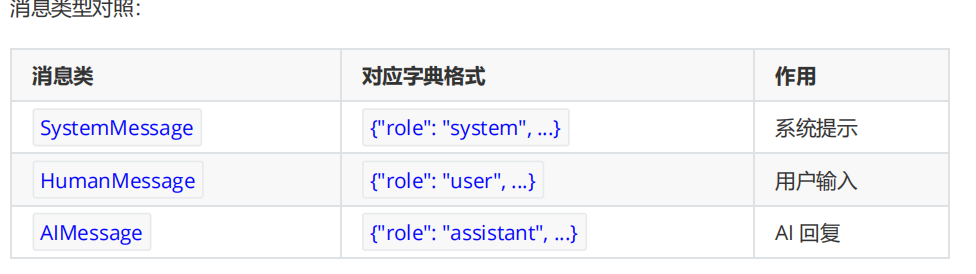
举例1
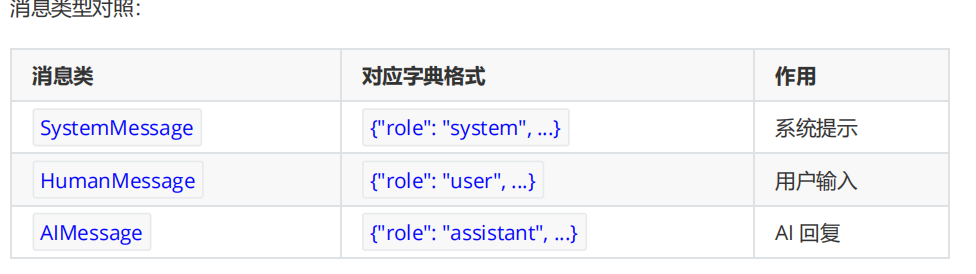

In [15]:
from langchain_core.messages import  SystemMessage,AIMessage,HumanMessage

messages = [
    SystemMessage("你是一个专业的数学老师"),
    HumanMessage("2 + 3 = ?"),
    AIMessage("5"),
    HumanMessage("我刚才问了什么问题"),
]
response3 = model.invoke(messages)
print(f"AI回复:{response3.content}")

AI回复:你刚才问的是：**“2 + 3 = ?”**  
我回答的是：**5**。


举例2

In [17]:
messages = [
    SystemMessage(content="你说一个Python专家"),
    HumanMessage(content="什么是langgragh"),
]
response = model.invoke(messages)
# print(response)
# 继续对话
messages.append(AIMessage(content=response.content))
messages.append(HumanMessage(content="能给我举个例子么"))
response1 = model.invoke(messages)
print(f"AI的回复2:{response1.content}")

AI的回复2:好，我用两个例子带你从「能跑」到「实战」。

---

## 例子 1：不用 LLM，先搞懂「循环 + 条件边」

假设有个任务：**不停地处理，直到结果达标为止，最多重试 5 次。**

```python
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

# 1. 定义状态
class State(TypedDict):
    value: int      # 当前值
    attempts: int   # 已尝试次数

# 2. 定义节点：每次把 value 加 3
def process(state: State):
    print(f"第 {state['attempts'] + 1} 次处理，当前 value = {state['value']}")
    return {
        "value": state["value"] + 3,
        "attempts": state["attempts"] + 1,
    }

# 3. 条件函数：决定下一步往哪走
def should_continue(state: State) -> str:
    if state["value"] >= 10:
        return "end"          # 达标，结束
    if state["attempts"] >= 5:
        return "end"          # 达到上限，结束
    return "continue"         # 否则继续循环

# 4. 构图
builder = StateGraph(State)
builder.add_node("process", process)

builder.add_edge(START, "process")
builder.add_conditional_edges(
    "process",
    should_continue,
    {
        "continue": "process",   # 回到自己，形成循环
        "end": END,
    },
)


## 5.1.3 返回值详解
from rich import print as rprint

In [19]:
from rich import print as rprint
response = model.invoke([HumanMessage("2 * 3 + 2 =?")])
rprint(response)

AIMessage(
    content='8',
    additional_kwargs={
        'refusal': None,
        'reasoning_content': 'We need answer simple arithmetic. Need obey? User asks "2 * 3 + 2 =?" Compute 
multiplication first 2*3=6 +2=8. Need final concise.'
    },
    response_metadata={
        'token_usage': {
            'completion_tokens': 41,
            'prompt_tokens': 39,
            'total_tokens': 80,
            'completion_tokens_details': {
                'accepted_prediction_tokens': None,
                'audio_tokens': None,
                'reasoning_tokens': 39,
                'rejected_prediction_tokens': None
            },
            'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 0},
            'prompt_cache_hit_tokens': 0,
            'prompt_cache_miss_tokens': 39
        },
        'model_provider': 'deepseek',
        'model_name': 'deepseek-flash',
        'system_fingerprint': 'aeb56401ca74e127821c4f9126dcb669',
        'id': '8512cbb1-c308-4a19-b712-cf5218b3043b',
        'finish_reason': 'stop',
        'logprobs': None
    },
    id='lc_run--01a0ec9e-5629-78a0-aacf-45e7fc684437-0',
    tool_calls=[],
    invalid_tool_calls=[],
    usage_metadata={
        'input_tokens': 39,
        'output_tokens': 41,
        'total_tokens': 80,
        'input_token_details': {'cache_read': 0},
        'output_token_details': {'reasoning': 39}
    }
)

举例2

In [20]:
response = model.invoke("用一句话解释什么是 AI")
# 1. 获取回复内容
print("AI 回复:", response.content)
# 2. 获取响应元数据
metadata = response.response_metadata
print(f"使用的模型: {metadata['model_name']}")
print(f"结束原因: {metadata['finish_reason']}")
print(f"模型提供商：{metadata['model_provider']}\n")
# 3. 获取 Token 使用情况
usage = metadata.get('token_usage', {})
print(f"输入 tokens: {usage.get('prompt_tokens')}")
print(f"输出 tokens: {usage.get('completion_tokens')}")
print(f"总计 tokens: {usage.get('total_tokens')}")
# 4. 获取消息 ID
print(f"消息 ID: {response.id}")

AI 回复: AI（人工智能）是让机器模拟人类智能，从而完成学习、推理、感知、决策等通常需要人类智能的任务的技术。
使用的模型: deepseek-flash
结束原因: stop
模型提供商：deepseek

输入 tokens: 35
输出 tokens: 100
总计 tokens: 135
消息 ID: lc_run--01a0eca1-3002-71b2-a55b-f5ff1291e5ff-0
